<a href="https://colab.research.google.com/github/100522371/P2_AA_Grupo17/blob/main/p2_grupo17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Montserrat Martis Contreras - 100522371

Laith Basem Elbeshti - 100477240

In [95]:
import pandas as pd

df = pd.read_csv('stars_data.csv')
df.head()

,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,Red,M
1,3042,0.000500,0.1542,16.60,Red,M
2,2600,0.000300,0.1020,18.70,Red,M
3,2800,0.000200,0.1600,16.65,Red,M
4,1939,0.000138,0.1030,20.06,Red,M


La codificación ordinal es una técnica de preparación de datos en aprendizaje automático que se utiliza para transformar variables categóricas en números enteros, basándose en que existe un orden o jerarquía natural entre esas categorías.

Sabemos que Spectral_Class tiene 7 posibles valores (O, B, A, F, G, K, M) que van desde lo mas frio a lo mas caliente. Esto lo podemos transformar a valores númericos del 0 al 6.

In [96]:
print(df['Spectral_Class'].unique())

['M' 'B' 'A' 'F' 'O' 'K' 'G']


En el documento solo aparecen tres colores principales rojo, amarillo y blanco.

---



In [97]:
print(df['Color'].unique())

['Red' 'Blue White' 'White' 'Yellowish White' 'Blue white'
 'Pale yellow orange' 'Blue' 'Blue-white' 'Whitish' 'yellow-white'
 'Orange' 'White-Yellow' 'white' 'yellowish' 'Yellowish' 'Orange-Red'
 'Blue-White']


Pero como podemos ver, hay más colores y algunos estan repetidos. Antes de codificarlos, vamos a arreglar esto

In [98]:
df['Color'] = df['Color'].str.lower()
def clean_color(color):
    if 'blue white' in color or 'blue-white' in color:
        return 'Blue-White'
    elif 'yellowish white' in color or 'white-yellow' in color or 'yellow-white' in color:
        return 'White-Yellow'
    elif 'pale yellow orange' in color:
        return 'Yellow-Orange'
    elif 'whitish' in color or 'white' in color:
        return 'White'
    elif 'yellowish' in color or 'yellow' in color:
        return 'Yellow'
    elif 'orange-red' in color:
        return 'Orange-Red'
    elif 'orange' in color:
        return 'Orange'
    elif 'red' in color:
        return 'Red'
    elif 'blue' in color:
        return 'Blue'
    else:
        return 'Other'

df['Color'] = df['Color'].apply(clean_color)
print(df['Color'].unique())

['Red' 'Blue-White' 'White' 'White-Yellow' 'Yellow-Orange' 'Blue' 'Orange'
 'Yellow' 'Orange-Red']


Ahora los colores reflejan una escala de temperatura, desde el más frío (Rojo) hasta el más caliente (Azul). Para mantener el orden de temperatura, se traducen a números del 0 al 8, donde los colores principales toman valores pares y los colores intermedios (como Orange-Red o Blue-White) toman los valores impares.

In [99]:
# Mapeo de la Clase Espectral de mas fria (M) a mas caliente (O)
spectral_mapping = {'M': 0, 'K': 1, 'G': 2, 'F': 3, 'A': 4, 'B': 5, 'O': 6}
df['Spectral_Class'] = df['Spectral_Class'].map(spectral_mapping)

# Mapeo de los colores basándonos en la temperatura (rojo es mas frio, azul es mas caliente)
color_mapping = {
    'Red': 0,
    'Orange-Red': 1,
    'Orange': 2,
    'Yellow-Orange': 3,
    'Yellow': 4,
    'White-Yellow': 5,
    'White': 6,
    'Blue-White': 7,
    'Blue': 8,
}
df['Color'] = df['Color'].map(color_mapping)

df.head()

,Temperature,L,R,A_M,Color,Spectral_Class
0,3068,0.002400,0.1700,16.12,0,0
1,3042,0.000500,0.1542,16.60,0,0
2,2600,0.000300,0.1020,18.70,0,0
3,2800,0.000200,0.1600,16.65,0,0
4,1939,0.000138,0.1030,20.06,0,0


In [100]:
df.shape

(240, 6)

# PCA

En esta sección buscamos resumir la información de todas las columnas (6 variables) en solo dos nuevas variables o dimensiones (las componentes principales), perdiendo la menor cantidad de información o varianza posible.

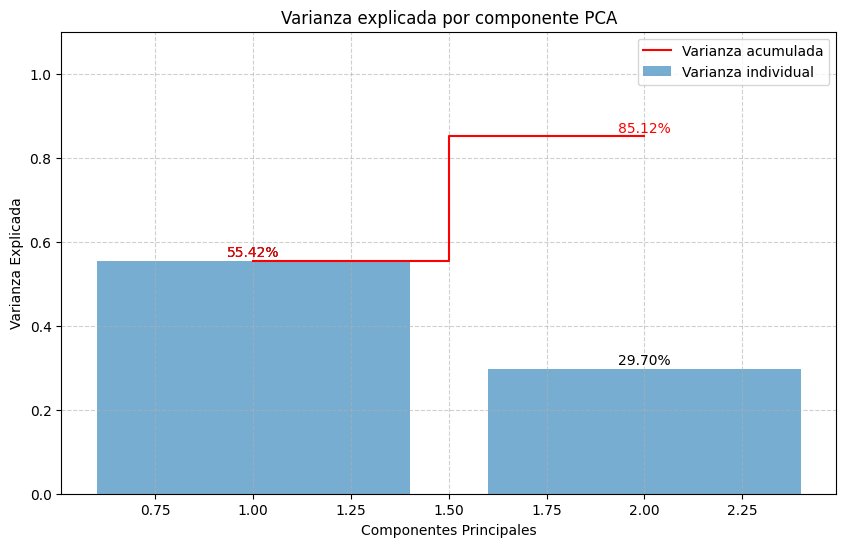

In [101]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import numpy as np

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=100522371))
])

df_pca = pipeline.fit_transform(df)
df_og = df.copy()
# convertimos el df_pca en un dataframe que podemos manipular
df = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])
pca = pipeline.named_steps['pca']

# Varianza explicada y acumulada
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Plot de Varianza Explicada y Acumulada
plt.figure(figsize=(10, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.6, label='Varianza individual')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid', label='Varianza acumulada', color='red')

# Añadir valores exactos
for i, (ev, cv) in enumerate(zip(explained_variance, cumulative_variance)):
    plt.text(i + 1, ev + 0.01, f"{ev:.2%}", ha='center')
    plt.text(i + 1, cv + 0.01, f"{cv:.2%}", ha='center', color='red')

plt.xlabel('Componentes Principales')
plt.ylabel('Varianza Explicada')
plt.title('Varianza explicada por componente PCA')
plt.legend(loc='best')
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

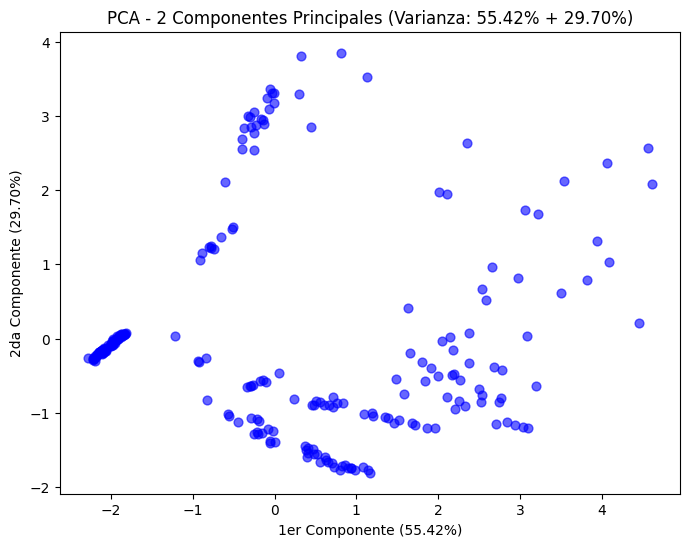

In [102]:
# Visualizar 2 componentes
# No tenemos un target como en el ejemplo, asi que hacemos un plot de color sólido
plt.figure(figsize=(8, 6))
plt.scatter(df_pca[:, 0], df_pca[:, 1], c='blue', s=40, alpha=0.6)
plt.title('PCA - 2 Componentes Principales (Varianza: {:.2%} + {:.2%})'.format(explained_variance[0], explained_variance[1]))
plt.xlabel('1er Componente ({:.2%})'.format(explained_variance[0]))
plt.ylabel('2da Componente ({:.2%})'.format(explained_variance[1]))
plt.show()

In [103]:
df.head()

,PC1,PC2
0,-2.076410,-0.141135
1,-2.095980,-0.158994
2,-2.197765,-0.229721
3,-2.109804,-0.155463
4,-2.282131,-0.267054


#K-Means

Para este algoritmo debemos encontrar el hiperparámetro K óptimo. K representa el número de clusters. Buscaremos en un rango de 2 a 15, y combinaremos dos técnicas: Elbow y Silhouette.

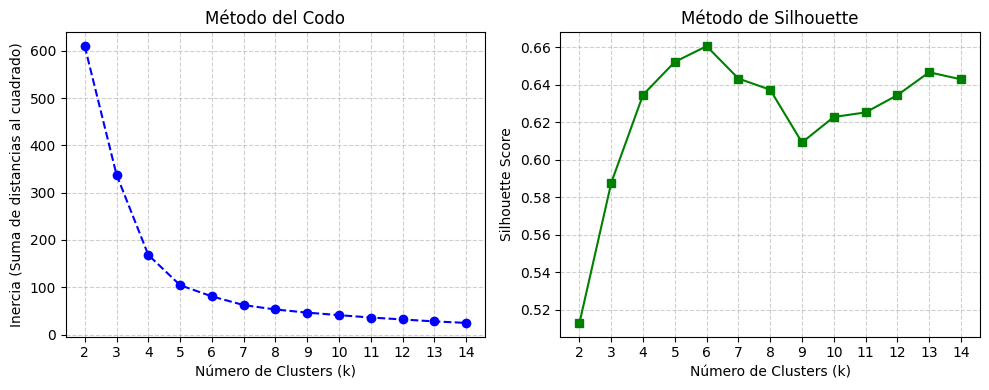

In [104]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rango_k = range(2, 15)
inercias = []
silhouette_scores = []

for k in rango_k:
    # Usamos n_init='auto' para evitar warnings en versiones recientes de scikit-learn??
    # random_state es el NIA base + 1 para que sea reproducible
    kmeans = KMeans(n_clusters=k, random_state=100522372, n_init=25)
    kmeans.fit(df)
    # Guardamos la inercia para Elbow
    inercias.append(kmeans.inertia_)
    # Guardamos el score de Silhouette
    score = silhouette_score(df, kmeans.labels_)
    silhouette_scores.append(score)

# --- Representación Gráfica ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Elbow
ax1.plot(rango_k, inercias, marker='o', linestyle='--', color='blue')
ax1.set_title('Método del Codo')
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inercia (Suma de distancias al cuadrado)')
ax1.set_xticks(rango_k)
ax1.grid(True, linestyle='--', alpha=0.6)

# Silhouette
ax2.plot(rango_k, silhouette_scores, marker='s', linestyle='-', color='green')
ax2.set_title('Método de Silhouette')
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(rango_k)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Con el método del codo es más difici determinar el número óptimo, en el gráfico no aparece un punto claro que aparente ser un codo. Aunque si se puede observar una zona de candidatos entre el 5, 6 y 7.

Gracias al método Silhouette logramos un desempate y demuestra en su gráfico que el mejor hiperparámetro es K=6.

Tiempo de ejecución: 0.06 segundos


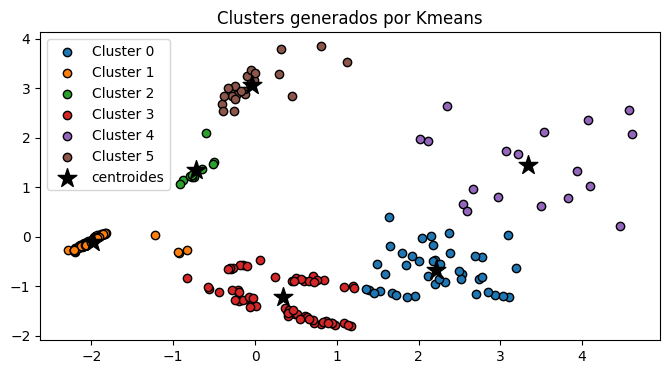

In [105]:
import time

t0 = time.time()
modelo_kmeans = KMeans(n_clusters=6, n_init=25, random_state=100522372)
modelo_kmeans.fit(df)
y_predict = modelo_kmeans.predict(df)
tf= time.time()
print(f"Tiempo de ejecución: {tf-t0:.2f} segundos")

fig, ax = plt.subplots(1, 1, figsize=(8, 4))

for i in np.unique(y_predict):
    ax.scatter(
        x = df.loc[y_predict == i, 'PC1'],
        y = df.loc[y_predict == i, 'PC2'],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black',
        label= f"Cluster {i}"
    )

ax.scatter(
    x = modelo_kmeans.cluster_centers_[:, 0],
    y = modelo_kmeans.cluster_centers_[:, 1],
    c = 'black',
    s = 200,
    marker = '*',
    label  = 'centroides'
)
ax.set_title('Clusters generados por Kmeans')
ax.legend();

# Hierarchical Clustering / Dendrogramas

Vamos a utilizar una aproximación aglomerativa empleando el método de enlace **Ward** ya que su objetivo es minimizar la varianza total dentro de los clusters (intra-cluster). A diferencia de otros criterios como 'single' o 'complete', tiende a producir agrupaciones más compactas y equilibradas, lo que se alinea mejor con la distribución de los datos estelares tras hacer PCA. Además, este método es menos sensible al ruido presente en los datos astronómicos y facilita una interpretación más clara de las jerarquías en el dendrograma para determinar el número óptimo de clusters.

 Para encontrar el número óptimo de clusters utilizaremos las dos técnicas aprendidas:
1. **Método Silhouette:** Evaluación de la distancia media intraclúster iterando entre diferentes valores de K.
2. **Salto en alturas de fusión del Dendrograma:** Determinaremos matemáticamente dónde se produce el mayor salto entre las alturas del particionado para definir el momento de corte de las uniones intra-cluster.

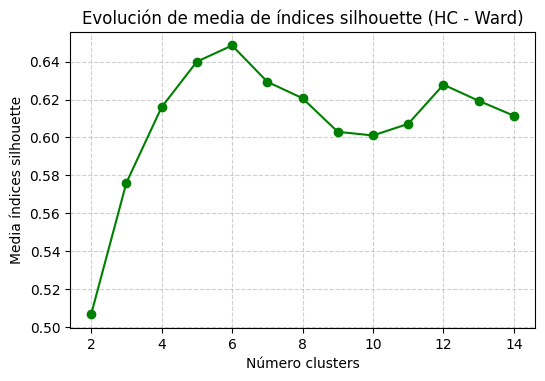

In [115]:
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# silhouette para identificar el número óptimo de clusters
range_n_clusters = range(2, 15)
valores_medios_silhouette_hc = []

for n_clusters in range_n_clusters:
    modelo_hc = AgglomerativeClustering(
        metric   = 'euclidean',
        linkage    = 'ward',
        n_clusters = n_clusters
    )
    cluster_labels_hc = modelo_hc.fit_predict(df)
    silhouette_avg_hc = silhouette_score(df, cluster_labels_hc)
    valores_medios_silhouette_hc.append(silhouette_avg_hc)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette_hc, marker='o', color='green')
ax.set_title("Evolución de media de índices silhouette (HC - Ward)")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette')
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

Número óptimo de clusters (según mayor salto): 2
Altura de fusión óptima: 22.24


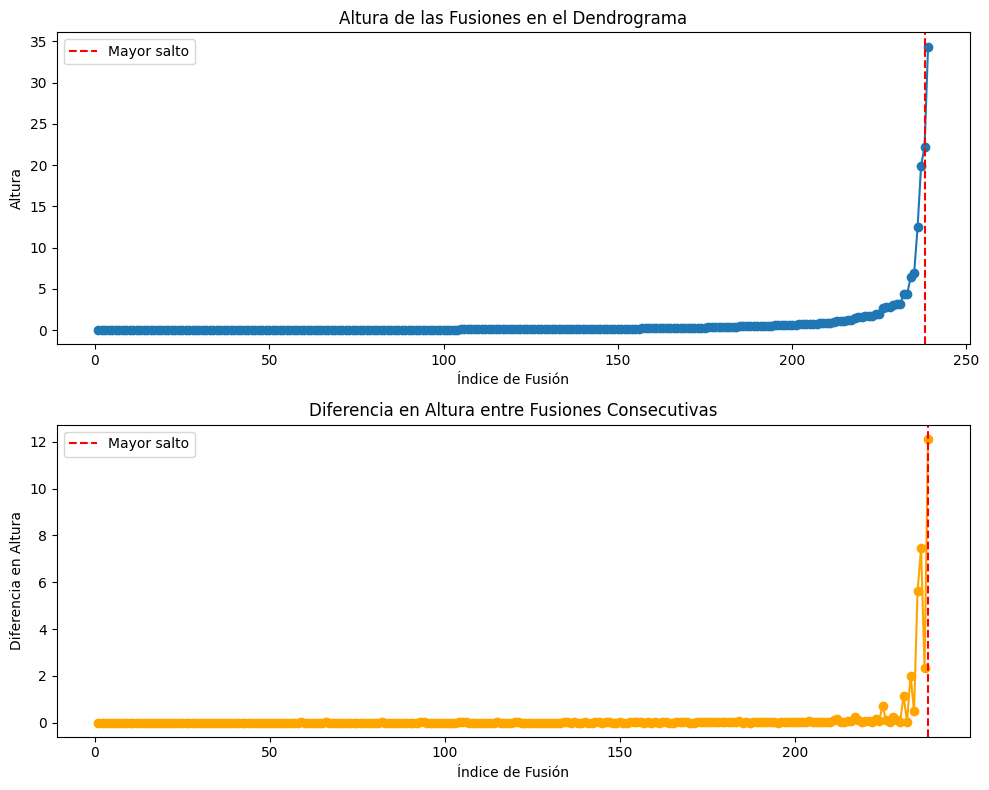

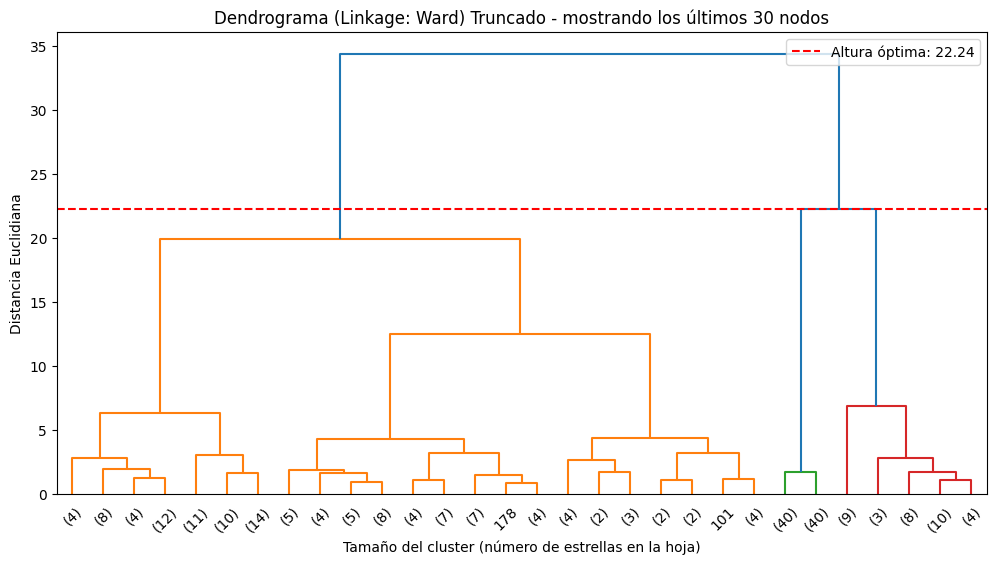

In [107]:
# Análisis del salto más grande en el Dendrograma (Linkage Ward)
Z = sch.linkage(df, method='ward')
heights = Z[:, 2]
diffs = np.diff(heights)
idx_max_jump = np.argmax(diffs)
n_clusters_optimo = len(heights) - idx_max_jump
altura_optima = heights[idx_max_jump]

print(f"Número óptimo de clusters (según mayor salto): {n_clusters_optimo}")
print(f"Altura de fusión óptima: {altura_optima:.2f}")

fig, ax = plt.subplots(2, 1, figsize=(10, 8))
ax[0].plot(range(1, len(heights) + 1), heights, marker='o', linestyle='-')
ax[0].set_title("Altura de las Fusiones en el Dendrograma")
ax[0].set_xlabel("Índice de Fusión")
ax[0].set_ylabel("Altura")
ax[0].axvline(x=idx_max_jump + 1, color='r', linestyle='--', label="Mayor salto")
ax[0].legend()

ax[1].plot(range(1, len(diffs) + 1), diffs, marker='o', linestyle='-', color='orange')
ax[1].set_title("Diferencia en Altura entre Fusiones Consecutivas")
ax[1].set_xlabel("Índice de Fusión")
ax[1].set_ylabel("Diferencia en Altura")
ax[1].axvline(x=idx_max_jump + 1, color='r', linestyle='--', label="Mayor salto")
ax[1].legend()

plt.tight_layout()
plt.show()

# Dendrograma con corte óptimo visualizado
plt.figure(figsize=(12, 6))
# Se usa `truncate_mode='lastp'` para no mostrar las 240 etiquetas superpuestas
sch.dendrogram(Z, color_threshold=altura_optima, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.axhline(y=altura_optima, color='r', linestyle='dashed', label=f'Altura óptima: {altura_optima:.2f}')
plt.title("Dendrograma (Linkage: Ward) Truncado - mostrando los últimos 30 nodos")
plt.xlabel("Tamaño del cluster (número de estrellas en la hoja)")
plt.ylabel("Distancia Euclidiana")
plt.legend()
plt.show()

Tal y como se puede observar tras seguir ambos métodos de análisis detallados en el tutorial:

- El método de **Silhouette** respalda de manera clara el uso de `K=6` (donde alcanza el pico de mayor definición), coincidiendo con el modelo K-Means previo.
- El análisis automatizado del **mayor salto en el dendrograma** es útil, pero al fijarse únicamente en la partición más tardía puede sugerir un número muy pequeño de formaciones macro.

Adicionalmente, de cara a facilitar la lectura del dendrograma dado que poseemos 240 muestras de estrellas distintas, hemos optado por truncarlo gráficamente para mostrar exclusivamente la capa superior de agrupamientos.

Tiempo de ejecución: 0.01 segundos


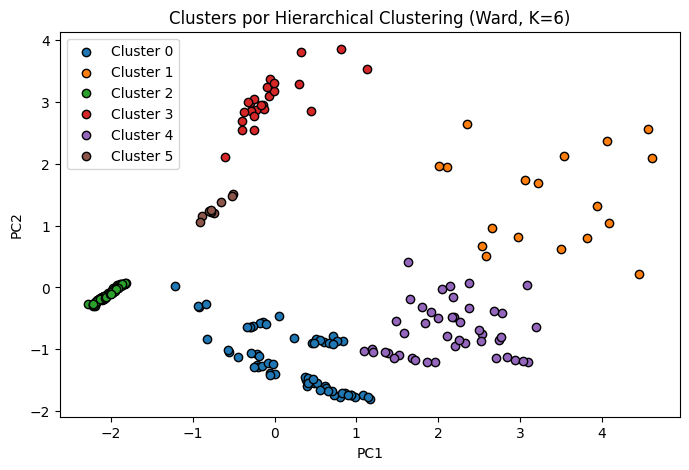

In [108]:
# Entrenamos el modelo final
t0 = time.time()
modelo_hc_final = AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='ward')
y_hc_final = modelo_hc_final.fit_predict(df)
tf= time.time()
print(f"Tiempo de ejecución: {tf-t0:.2f} segundos")

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
for i in np.unique(y_hc_final):
    ax.scatter(
        x = df.loc[y_hc_final == i, 'PC1'],
        y = df.loc[y_hc_final == i, 'PC2'],
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i % 10],
        marker    = 'o',
        edgecolor = 'black',
        label= f"Cluster {i}"
    )
ax.set_title(f'Clusters por Hierarchical Clustering (Ward, K=6)')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(loc='best')
plt.show()

Por tanto, el modelo aglomerativo final lo hemos instanciado con `K=6`, mostrando unos agrupamientos que, al visualizarlos, separan el espacio de características de un modo muy consolidado y parecido a como lo hizo K-Means.

# DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) es un algoritmo de agrupamiento basado en la densidad espacial, que encuentra regiones centrales de alta densidad y las expande para formar agrupamientos.

A diferencia de K-Means o Jerárquico, DBSCAN no requiere que especifiquemos `K` a priori, pero necesita que fijemos en sintonía dos hiperparámetros críticos:
1. `min_samples`: Mínimo de observaciones dentro de un radio para considerar a un punto "core".
2. `eps`: El radio máximo de vecindad de cada punto.

Para encontrar el radio ideal (`eps`) utilizaremos un gráfico *k-distance*, evaluando el codo basándonos sistemáticamente en la distancia con el k-ésimo vecino más próximo. Seguidamente usaremos la métrica `DBCV` para verificar cuantitativamente nuestros resultados.

In [109]:
# Instalación de la métrica específica DBCV
!pip install "git+https://github.com/FelSiq/DBCV"

  Cloning https://github.com/FelSiq/DBCV to /tmp/pip-req-build-eiufbyo9
  Running command git clone --filter=blob:none --quiet https://github.com/FelSiq/DBCV /tmp/pip-req-build-eiufbyo9
  Resolved https://github.com/FelSiq/DBCV to commit 13c3896ef78d12f1e3e1cbd394f2db9a09637ffd
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


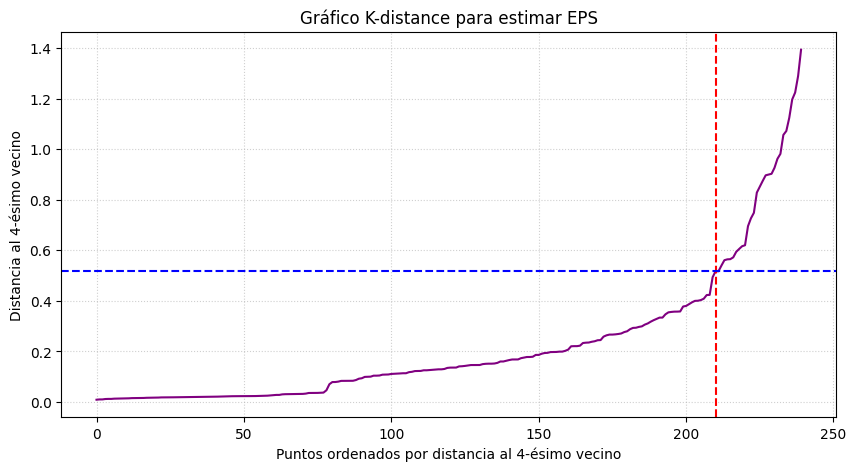

Heurística estimada: Para punto=210, EPS sugerido=0.5174


In [110]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
import dbcv

# Análisis del k-distance para calcular un EPS inicial (Heurística)
# Fijamos min_samples en 5 por tratarse de un conjunto 2D estándar y sin demasiada densidad
min_samples = 5

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(df)
distances, indices = nn.kneighbors(df)

# Ordenamos las distancias del k-ésimo vecino (min_samples - 1 es el índice)
sorted_distances = np.sort(distances[:, min_samples-1], axis=0)

# Al observar la lista, el codo / subida fuerte en nuestro dataset de PCA ocurre aprox alrededor del pto 210
x_point = 210
y_value_eps = sorted_distances[x_point]

plt.figure(figsize=(10, 5))
plt.plot(sorted_distances, color='purple')
plt.xlabel(f'Puntos ordenados por distancia al {min_samples-1}-ésimo vecino')
plt.ylabel(f'Distancia al {min_samples-1}-ésimo vecino')
plt.title('Gráfico K-distance para estimar EPS')
plt.axvline(x=x_point, color='r', linestyle='--')
plt.axhline(y=y_value_eps, color='b', linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"Heurística estimada: Para punto={x_point}, EPS sugerido={y_value_eps:.4f}")


MS  | EPS  | Nº Clusters | % Ruido  | DBCV Score
-------------------------------------------------------
5   | 0.45 | 4           |    12.5% | 0.8230
5   | 0.50 | 4           |     9.6% | 0.8348
5   | 0.55 | 4           |     7.1% | 0.6431
5   | 0.60 | 4           |     5.8% | 0.6062
5   | 0.65 | 2           |     5.8% | 0.4075
6   | 0.45 | 4           |    12.5% | 0.8230
6   | 0.50 | 4           |    10.8% | 0.8352
6   | 0.55 | 4           |     9.2% | 0.6937
6   | 0.60 | 4           |     8.3% | 0.7240
6   | 0.65 | 2           |     7.1% | 0.4060
7   | 0.45 | 4           |    12.5% | 0.8230
7   | 0.50 | 4           |    11.2% | 0.8317
7   | 0.55 | 4           |     9.6% | 0.6915
7   | 0.60 | 4           |     8.3% | 0.7240
7   | 0.65 | 4           |     7.5% | 0.1466

Recomendación de Hiperparámetros DBSCAN por DBCV:
--> EPS=0.50, Min_Samples=6 con Score DBCV=0.8352
Número de outliers encontrados: 26


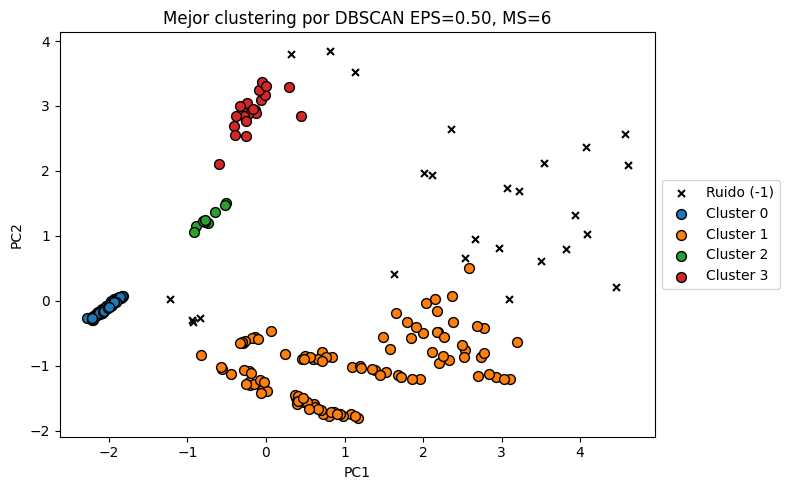

In [111]:
# Fine-tuning iterativo midiendo con la métrica DBCV
min_samples_values = [5, 6, 7]
# Generamos márgenes eps alrededor de nuestro punto estimado heurísticamente
eps_values = [0.45, 0.50, 0.55, 0.60, 0.65]

print(f"\n{'MS':<3} | {'EPS':<4} | {'Nº Clusters':<11} | {'% Ruido':<8} | {'DBCV Score'}")
print("-" * 55)

best_score = -2.0
best_params = {}
best_labels = None

# Pasamos el dataframe de PCA a array numpy (DBCV lo requiere para trabajar sin fallos internos)
X_numpy = df.to_numpy()

for ms in min_samples_values:
    for e in eps_values:
        db = DBSCAN(eps=e, min_samples=ms, metric='euclidean').fit(X_numpy)
        labels = db.labels_

        n_clusters_db = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise_db = list(labels).count(-1)
        perc_noise_db = (n_noise_db / len(labels)) * 100

        if n_clusters_db > 1:
            try:
                # Calcular la métrica de calidad
                score = dbcv.dbcv(X_numpy, labels)
                print(f"{ms:<3} | {e:<4.2f} | {n_clusters_db:<11} | {perc_noise_db:>7.1f}% | {score:.4f}")

                # Guardar el mejor
                if score > best_score:
                    best_score = score
                    best_params = {'eps': e, 'min_samples': ms}
                    best_labels = labels
            except ValueError:
                # DBCV a veces produce ValueError si un cluster completo está compuesto de ruido o no tiene var matemática calculable
                print(f"{ms:<3} | {e:<4.2f} | {n_clusters_db:<11} | {perc_noise_db:>7.1f}% | Error DBCV")
        else:
            print(f"{ms:<3} | {e:<4.2f} | {n_clusters_db:<11} | {perc_noise_db:>7.1f}% | No calculable (1 cluster)")

# Ploteamos el mejor resultado encontrado por DBCV
print(f"\nRecomendación de Hiperparámetros DBSCAN por DBCV:")
print(f"--> EPS={best_params['eps']:.2f}, Min_Samples={best_params['min_samples']} con Score DBCV={best_score:.4f}")
n_noise    = list(best_labels).count(-1)
print(f'Número de outliers encontrados: {n_noise}')

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

# Plot ruido (-1)
ax.scatter(
    x = df.loc[best_labels == -1, 'PC1'],
    y = df.loc[best_labels == -1, 'PC2'],
    c = 'black',
    marker = 'x',
    s = 25,
    label = 'Ruido (-1)'
)

# Plot clusters
for i in set(best_labels):
    if i != -1: # Saltamos el ruido
        ax.scatter(
            x = df.loc[best_labels == i, 'PC1'],
            y = df.loc[best_labels == i, 'PC2'],
            c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i % 10],
            marker    = 'o',
            edgecolor = 'black',
            s = 50,
            label= f"Cluster {i}"
        )

ax.set_title(f'Mejor clustering por DBSCAN EPS={best_params["eps"]:.2f}, MS={best_params["min_samples"]}')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
# Desplazamos la leyenda si hay muchos clusters para que no tape
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Tras el proceso de ajuste utilizando la métrica DBCV (Density-Based Cluster Validation), se determinaron los hiperparámetros óptimos:

*   `eps`: 0.50
*   `min_Samples`: 6

Con estos parámetros, DBSCAN identificó 4 clusters con un DBCV Score de 0.8352, lo que indica una buena densidad y separación entre los grupos. Además, el algoritmo detectó 26 puntos como ruido, lo que representa aproximadamente el 10.8% de los datos.

#Conclusiones

Aunque DBSCAN obtuvo una alta puntuación de densidad (DBCV = 0.8352), formando 4 clusters muy sólidos, recomendamos el pipeline basado en Clustering Jerárquico con linkage de Ward y k=6.

La justificación principal es  la clasificación real dada en el punto 5 del enunciado establece 6 tipos de estrellas principales. Al utilizar Ward con k=6, el algoritmo logra encontrar esas 6 divisiones naturales minimizando la varianza interna. DBSCAN, al guiarse puramente por densidad espacial, termina fusionando categorías que en la realidad son distintas pero comparten valores parecidos (por ejemplo, la Enana Roja y la Marrón).

Otra característica que nos hace favorecer Clustering Jerárquico sobre KMeans es el hecho que tarda ligeramente menos en entrenar el modelo. La diferencia es negligible pero queríamos un punto de desempate.

En conclusión, el pipeline que recomendamos sería el siguiente:
1. **Transformación de Variables Categóricas**: Mapeo de las variables Color y Clase Espectral a valores numéricos respetando su relación física con la temperatura y la energía de la estrella (ej. Rojo=0, Azul=8; M=0, O=6).
2. **Escalado**: Aplicación de `StandardScaler` para estandarizar todas las variables y evitar que magnitudes dispares (como la Temperatura frente a la Luminosidad) dominen el cálculo de distancias.
3. **PCA**: Con dos componentes y semilla fijada para simplificar el espacio de características conservando la mayor cantidad de varianza posible (~85%)
4. **Clustering**: `AgglomerativeClustering` utilizando el método de linkage de Ward y número de clusters igual a 6.

In [112]:
# Definimos los pasos del pipeline
pipeline_steps = [
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=100522371)),
    ('agg_clustering', AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='ward'))
]
recommended_pipeline = Pipeline(steps=pipeline_steps)

# df_og es el DataFrame con las variables 'Color' y 'Spectral_Class' ya mapeadas numéricamente.
recommended_pipeline.fit(df_og)

Pipeline(steps=[('scaler', StandardScaler()),
                ('pca', PCA(n_components=2, random_state=100522371)),
                ('agg_clustering', AgglomerativeClustering(n_clusters=6))])

#Comparación con tipos de estrellas


In [113]:
# Añadimos las predicciones de cluster al dataframe anterior al pca
modelo_final = AgglomerativeClustering(n_clusters=6, linkage='ward', metric='euclidean')
etiquetas_finales = modelo_final.fit_predict(df) # cogemos las predicciones
# y las añadimos al dataframe original
df_og['Cluster_Predicho'] = etiquetas_finales

# Agrupamos por cluster y calculamos la media
resumen_clusters = df_og.groupby('Cluster_Predicho').mean()

# Formatear 'L' y 'R' en notación científica
display(resumen_clusters.style.format({'L': '{:.2e}', 'R': '{:.2e}'}))

,Temperature,L,R,A_M,Color,Spectral_Class
Cluster_Predicho,,,,,,
0,11845.428571,7.95e+01,9.98e-01,8.760365,6.365079,3.936508
1,24015.888889,5.12e+05,1.11e+03,-8.730667,7.500000,5.444444
2,3140.887500,3.05e-03,2.29e-01,15.051737,0.000000,0.000000
3,3776.080000,2.39e+05,1.37e+03,-9.929600,0.160000,0.160000
4,21425.044444,1.90e+05,4.98e+01,-5.358778,7.711111,5.666667
5,3449.222222,2.21e+05,4.66e+01,-6.414444,0.000000,0.000000


Al analizar las medias de las características físicas de cada uno de los 6 clústeres generados por nuestro modelo y compararlas con la tabla de referencia, observamos que la distribución del algoritmo no sigue las clases de referencia. Esto es algo de esperar ya que los datos proporcionados tienen valores más variados que los que aparecen en las clases de estrellas descritas en el punto 5.

La correspondencia de ambos grupos es la siguiente:
- **Clúster 2** (Enanas Rojas y Enanas Marrones): Este grupo encaja perfectamente con las dos primeras clases de la tabla. Presenta una temperatura media muy baja ($\approx 3140$ K), una luminosidad y radio minúsculos ($L \approx 0.003$, $R \approx 0.22$), y la magnitud absoluta más alta ($\approx 15.05$). Su color predominante es el rojo (0). Dado que las enanas rojas y marrones son casi idénticas físicamente en estos atributos, el modelo las agrupa lógicamente juntas.
- **Clúster 0** (Secuencia Principal y Enanas Blancas): Este grupo representa estrellas de tamaño medio y pequeño, pero muy calientes. Tienen un radio promedio cercano al del sol ($R \approx 1.0$), temperaturas medias-altas ($\approx 11845$ K) y colores dominantes en el espectro blanco/blanco-amarillo. Representan una transición perfecta entre las Enanas Blancas y la Secuencia Principal de la tabla.
- **Clúster 5** (Supergigantes Rojas): Coincide con la categoría de "Super gigante". Poseen radios masivos ($R \approx 46.6$), una altísima luminosidad, pero temperaturas bajas ($\approx 3449$ K) ligadas a un color rojo y magnitud absoluta negativa ($-6.41$).
- **Clúster 4** (Supergigantes Azules/Calientes): También pertenecen a la clase "Super gigante" (Radio $\approx 49.8$ y gran luminosidad), pero el algoritmo ha sido capaz de separarlas del Clúster 5 porque estas son extremadamente calientes ($\approx 21425$ K) y de colores blanco-azulados.
- **Clúster 3** (Hipergigantes Rojas): Encajan con la última fila de la tabla ("Hiper gigante"). Tienen radios colosales ($R \approx 1370$ veces el del sol) y luminosidades extremas, pero mantienen temperaturas superficiales bajas ($\approx 3776$ K) asociadas al color rojo.
- **Clúster 1** (Hipergigantes Azules/Calientes): Al igual que en las supergigantes, el algoritmo ha identificado un subgrupo de "Hiper gigantes" con radios masivos ($R \approx 1110$) y con temperaturas abrasadoras ($\approx 24015$ K) correspondientes a las estrellas más calientes (colores azules, clase espectral O/B).

# Declaración IA

Durante la realización de esta práctica, se ha empleado un asistente basado en Inteligencia Artificial como herramienta de apoyo para las siguientes tareas:

- Soporte en la resolución de errores (debugging) en Python.

Todos los contenidos generados por la IA han sido dirigidos y validados por los autores de la práctica. Asumimos la responsabilidad ética y académica sobre la integridad de los datos presentados, el funcionamiento del código y las decisiones estratégicas que concluyen en la selección del modelo final.